Environment Setup

In [1]:
# 1. Connect Drive (click "Allow" in the popup)
from google.colab import drive
drive.mount('/content/drive')

# 2. Folder paths
import os, glob
import pandas as pd

base = '/content/drive/MyDrive/Smog'
processed = f'{base}/processed'
os.makedirs(processed, exist_ok=True)   # makes the folder only if it's missing

# 3. Load all the raw files
aq = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{base}/air_quality_*.csv'))], ignore_index=True)
wx = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{base}/weather_*.csv'))], ignore_index=True)

# 4. Make the time column a real date
aq['time'] = pd.to_datetime(aq['time'])
wx['time'] = pd.to_datetime(wx['time'])

print(aq.shape, wx.shape)

Mounted at /content/drive
(220464, 7) (220464, 8)


Skimming:

In [2]:
print(aq.shape)
print(wx.shape)
aq.head()

(220464, 7)
(220464, 8)


,city,time,pm2_5,pm10,nitrogen_dioxide,ozone,us_aqi
0,Faisalabad,2022-08-01 00:00:00,NaN,NaN,NaN,NaN,NaN
1,Faisalabad,2022-08-01 01:00:00,NaN,NaN,NaN,NaN,NaN
2,Faisalabad,2022-08-01 02:00:00,NaN,NaN,NaN,NaN,NaN
3,Faisalabad,2022-08-01 03:00:00,NaN,NaN,NaN,NaN,NaN
4,Faisalabad,2022-08-01 04:00:00,NaN,NaN,NaN,NaN,NaN


In [3]:
aq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220464 entries, 0 to 220463
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   city              220464 non-null  object        
 1   time              220464 non-null  datetime64[ns]
 2   pm2_5             220002 non-null  float64       
 3   pm10              220002 non-null  float64       
 4   nitrogen_dioxide  220002 non-null  float64       
 5   ozone             220002 non-null  float64       
 6   us_aqi            219858 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 11.8+ MB


Does every City has same amount of data?

In [4]:
print(aq.groupby('city').size())
print(wx.groupby('city').size())

city
Faisalabad    36744
Islamabad     36744
Karachi       36744
Lahore        36744
Peshawar      36744
Quetta        36744
dtype: int64
city
Faisalabad    36744
Islamabad     36744
Karachi       36744
Lahore        36744
Peshawar      36744
Quetta        36744
dtype: int64


In [5]:
print(aq.groupby('city')['time'].agg(['min', 'max']))

                  min                 max
city                                     
Faisalabad 2022-08-01 2026-10-09 23:00:00
Islamabad  2022-08-01 2026-10-09 23:00:00
Karachi    2022-08-01 2026-10-09 23:00:00
Lahore     2022-08-01 2026-10-09 23:00:00
Peshawar   2022-08-01 2026-10-09 23:00:00
Quetta     2022-08-01 2026-10-09 23:00:00


Missing Values:

In [6]:
aq.isna().sum()

,0
city,0
time,0
pm2_5,462
pm10,462
nitrogen_dioxide,462
ozone,462
us_aqi,606


In [7]:
wx.isna().sum()

,0
city,0
time,0
temperature_2m,0
relative_humidity_2m,0
precipitation,0
wind_speed_10m,0
wind_direction_10m,0
surface_pressure,0


In [8]:
aq.isna().groupby(aq['city']).sum()

,city,time,pm2_5,pm10,nitrogen_dioxide,ozone,us_aqi
city,,,,,,,
Faisalabad,0,0,77,77,77,77,101
Islamabad,0,0,77,77,77,77,101
Karachi,0,0,77,77,77,77,101
Lahore,0,0,77,77,77,77,101
Peshawar,0,0,77,77,77,77,101
Quetta,0,0,77,77,77,77,101


Duplicates:

In [9]:
print(aq.duplicated(subset=['city', 'time']).sum())
print(wx.duplicated(subset=['city', 'time']).sum())

0
0


Strange Values:

In [10]:
aq.describe().T

,count,mean,min,25%,50%,75%,max,std
time,220464,2024-09-04 11:30:00.000000256,2022-08-01 00:00:00,2023-08-18 17:45:00,2024-09-04 11:30:00,2025-09-22 05:15:00,2026-10-09 23:00:00,NaN
pm2_5,220002.0,44.840799,0.3,21.1,33.8,53.8,486.2,39.807842
pm10,220002.0,75.739485,0.4,37.8,58.7,91.5,890.3,62.393536
nitrogen_dioxide,220002.0,29.839196,-1.4,7.3,18.7,42.4,317.7,30.810424
ozone,220002.0,81.79327,-12.0,39.0,74.0,117.0,680.0,55.550574
us_aqi,219858.0,116.798515,12.0,80.0,107.0,151.0,538.0,47.747965


In [11]:
wx.describe().T

,count,mean,min,25%,50%,75%,max,std
time,220464,2024-09-04 11:30:00.000000256,2022-08-01 00:00:00,2023-08-18 17:45:00,2024-09-04 11:30:00,2025-09-22 05:15:00,2026-10-09 23:00:00,NaN
temperature_2m,220464.0,23.093795,-9.0,16.9,24.6,29.5,46.9,8.630422
relative_humidity_2m,220464.0,58.301401,2.0,40.0,61.0,78.0,100.0,23.844285
precipitation,220464.0,0.068311,0.0,0.0,0.0,0.0,22.8,0.537024
wind_speed_10m,220464.0,7.815239,0.0,4.0,6.7,10.1,46.6,5.431673
wind_direction_10m,220464.0,191.793808,1.0,98.0,194.0,288.0,360.0,106.16149
surface_pressure,220464.0,956.002605,825.4,950.5,975.9,991.1,1024.4,55.99193


Where And How Many:

In [12]:
missing_pm = aq[aq['pm2_5'].isna()]
print(missing_pm.groupby('city')['time'].agg(['count', 'min', 'max']))

missing_aqi = aq[aq['us_aqi'].isna()]
print(missing_aqi.groupby('city')['time'].agg(['count', 'min', 'max']))

            count        min                 max
city                                            
Faisalabad     77 2022-08-01 2022-08-04 04:00:00
Islamabad      77 2022-08-01 2022-08-04 04:00:00
Karachi        77 2022-08-01 2022-08-04 04:00:00
Lahore         77 2022-08-01 2022-08-04 04:00:00
Peshawar       77 2022-08-01 2022-08-04 04:00:00
Quetta         77 2022-08-01 2022-08-04 04:00:00
            count        min                 max
city                                            
Faisalabad    101 2022-08-01 2022-08-05 04:00:00
Islamabad     101 2022-08-01 2022-08-05 04:00:00
Karachi       101 2022-08-01 2022-08-05 04:00:00
Lahore        101 2022-08-01 2022-08-05 04:00:00
Peshawar      101 2022-08-01 2022-08-05 04:00:00
Quetta        101 2022-08-01 2022-08-05 04:00:00


In [13]:
print((aq['nitrogen_dioxide'] < 0).sum())
print((aq['ozone'] < 0).sum())
print((aq['us_aqi'] > 500).sum())

12
131
9


In [14]:
aq[aq['us_aqi'] > 500][['city', 'time', 'pm2_5', 'us_aqi']]

,city,time,pm2_5,us_aqi
134858,Lahore,2025-05-23 02:00:00,163.9,520.0
134859,Lahore,2025-05-23 03:00:00,148.1,533.0
134860,Lahore,2025-05-23 04:00:00,133.2,538.0
134861,Lahore,2025-05-23 05:00:00,140.6,535.0
134862,Lahore,2025-05-23 06:00:00,131.8,529.0
134863,Lahore,2025-05-23 07:00:00,122.9,524.0
134864,Lahore,2025-05-23 08:00:00,110.1,519.0
134865,Lahore,2025-05-23 09:00:00,98.0,513.0
134866,Lahore,2025-05-23 10:00:00,93.1,504.0


In [15]:
aq[aq['us_aqi'] > 500][['time', 'pm2_5', 'pm10', 'ozone', 'us_aqi']]

,time,pm2_5,pm10,ozone,us_aqi
134858,2025-05-23 02:00:00,163.9,681.7,128.0,520.0
134859,2025-05-23 03:00:00,148.1,601.6,126.0,533.0
134860,2025-05-23 04:00:00,133.2,519.7,123.0,538.0
134861,2025-05-23 05:00:00,140.6,571.8,120.0,535.0
134862,2025-05-23 06:00:00,131.8,510.4,123.0,529.0
134863,2025-05-23 07:00:00,122.9,506.6,128.0,524.0
134864,2025-05-23 08:00:00,110.1,466.6,137.0,519.0
134865,2025-05-23 09:00:00,98.0,418.2,155.0,513.0
134866,2025-05-23 10:00:00,93.1,411.6,177.0,504.0


Cleaning

In [16]:
start = pd.Timestamp('2022-08-06')
aq_clean = aq[aq['time'] >= start].copy()
wx_clean = wx[wx['time'] >= start].copy()

for col in ['nitrogen_dioxide', 'ozone']:
    aq_clean[col] = aq_clean[col].clip(lower=0)
aq_clean['us_aqi'] = aq_clean['us_aqi'].clip(upper=500)

In [17]:
print(aq_clean.shape, wx_clean.shape)
print(aq_clean.isna().sum().sum())
print((aq_clean['ozone'] < 0).sum(), (aq_clean['us_aqi'] > 500).sum())

(219744, 7) (219744, 8)
0
0 0


Merge:

In [18]:
merged = aq_clean.merge(wx_clean, on=['city', 'time'], how='inner', validate='one_to_one')

print(merged.shape)
print(merged.isna().sum().sum())
merged.head()

(219744, 13)
0


,city,time,pm2_5,pm10,nitrogen_dioxide,ozone,us_aqi,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure
0,Faisalabad,2022-08-06 00:00:00,43.7,62.6,23.6,52.0,115.0,27.5,89,0.0,7.3,123,978.7
1,Faisalabad,2022-08-06 01:00:00,43.0,61.5,24.9,46.0,115.0,27.2,91,0.0,4.6,129,978.8
2,Faisalabad,2022-08-06 02:00:00,41.6,59.5,25.5,40.0,115.0,26.9,93,0.0,3.8,139,978.6
3,Faisalabad,2022-08-06 03:00:00,38.4,54.8,24.6,38.0,116.0,26.6,95,0.0,3.1,135,978.6
4,Faisalabad,2022-08-06 04:00:00,35.0,50.1,22.8,37.0,116.0,26.8,94,0.0,2.2,81,978.8


Check Point:

In [19]:
merged.to_csv(f'{processed}/merged_v1.csv', index=False)

Making a Daily Column

In [20]:
merged['date'] = merged['time'].dt.floor('D')

daily = merged.groupby(['city', 'date']).agg(
    pm2_5_mean=('pm2_5', 'mean'),
    pm2_5_max=('pm2_5', 'max'),
    pm10_mean=('pm10', 'mean'),
    no2_mean=('nitrogen_dioxide', 'mean'),
    ozone_mean=('ozone', 'mean'),
    aqi_mean=('us_aqi', 'mean'),
    aqi_max=('us_aqi', 'max'),
    temp_mean=('temperature_2m', 'mean'),
    humidity_mean=('relative_humidity_2m', 'mean'),
    rain_total=('precipitation', 'sum'),
    wind_mean=('wind_speed_10m', 'mean'),
    pressure_mean=('surface_pressure', 'mean'),
    hours=('time', 'count'),
).reset_index()

In [21]:
print(daily.shape)
print((daily['hours'] != 24).sum())
print(daily.isna().sum().sum())
daily.head()

(9156, 15)
0
0


,city,date,pm2_5_mean,pm2_5_max,pm10_mean,no2_mean,ozone_mean,aqi_mean,aqi_max,temp_mean,humidity_mean,rain_total,wind_mean,pressure_mean,hours
0,Faisalabad,2022-08-06,42.370833,74.3,60.775000,17.608333,104.083333,126.083333,165.0,29.708333,78.625000,0.0,5.845833,977.991667,24
1,Faisalabad,2022-08-07,51.312500,76.8,74.945833,20.833333,111.166667,141.041667,171.0,30.804167,73.125000,0.3,6.437500,977.170833,24
2,Faisalabad,2022-08-08,47.550000,84.5,71.525000,32.700000,106.791667,134.333333,178.0,30.991667,73.375000,0.1,8.195833,978.029167,24
3,Faisalabad,2022-08-09,56.050000,94.1,81.991667,45.979167,87.958333,150.291667,159.0,31.991667,67.333333,0.0,5.987500,978.141667,24
4,Faisalabad,2022-08-10,61.733333,87.8,89.070833,43.320833,99.208333,155.666667,185.0,32.625000,66.458333,0.0,3.470833,976.245833,24


Checkpoint 2:

In [22]:
daily.to_csv(f'{processed}/daily_v1.csv', index=False)

Charts for EDA:

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

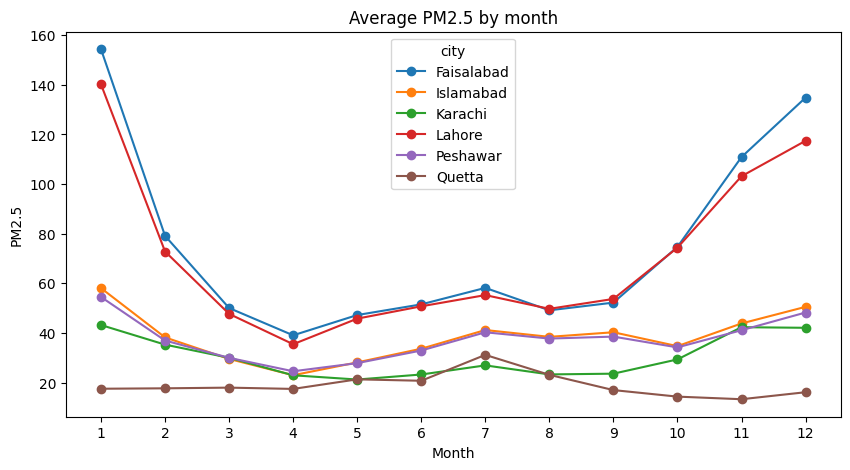

In [24]:
# Month Pattern
daily['month'] = daily['date'].dt.month

monthly = daily.groupby(['month', 'city'])['pm2_5_mean'].mean().unstack()

monthly.plot(figsize=(10, 5), marker='o')
plt.title('Average PM2.5 by month')
plt.xlabel('Month')
plt.ylabel('PM2.5')
plt.xticks(range(1, 13))
plt.show()

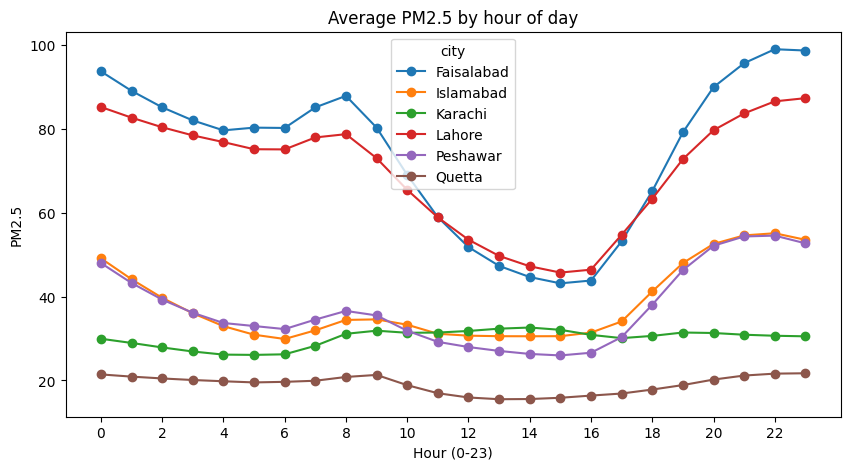

In [25]:
# Hour-of-day Pattern
merged['hour'] = merged['time'].dt.hour

hourly = merged.groupby(['hour', 'city'])['pm2_5'].mean().unstack()

hourly.plot(figsize=(10, 5), marker='o')
plt.title('Average PM2.5 by hour of day')
plt.xlabel('Hour (0-23)')
plt.ylabel('PM2.5')
plt.xticks(range(0, 24, 2))
plt.show()

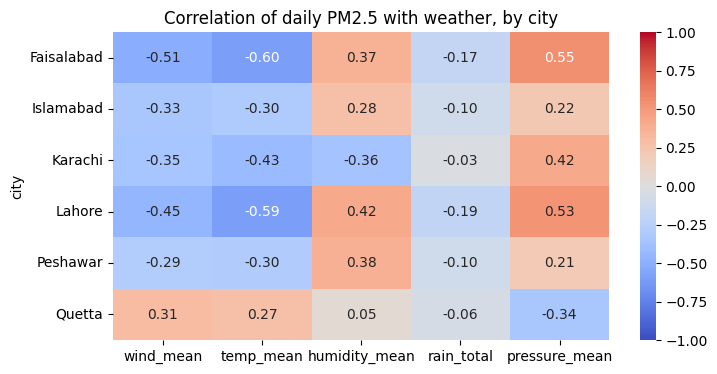

In [26]:
# PM2.5 and weather
cols = ['pm2_5_mean', 'wind_mean', 'temp_mean', 'humidity_mean', 'rain_total', 'pressure_mean']

corr = daily.groupby('city')[cols].corr()['pm2_5_mean'].unstack().drop(columns='pm2_5_mean')

plt.figure(figsize=(8, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of daily PM2.5 with weather, by city')
plt.show()

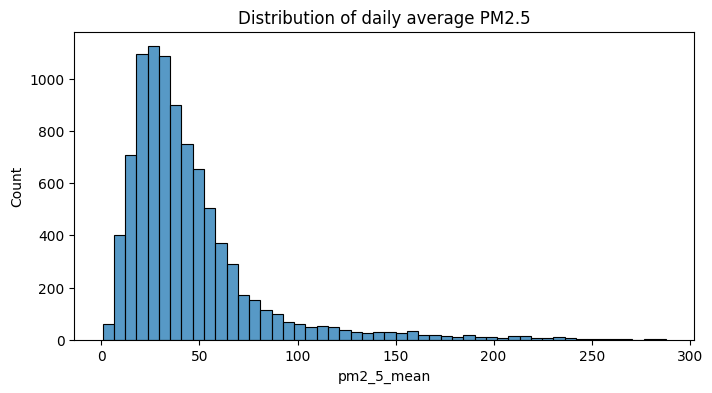

In [27]:
# How spread is PM2.5
plt.figure(figsize=(8, 4))
sns.histplot(daily['pm2_5_mean'], bins=50)
plt.title('Distribution of daily average PM2.5')
plt.show()

<h2> Week M2: </h2>
Data Lead:

In [28]:
# Load
daily = pd.read_csv(f'{processed}/daily_v1.csv', parse_dates=['date'])

In [31]:
# AQI Bands
bins = [0, 50, 100, 150, 200, 300, 500]
labels = ['Good', 'Moderate', 'Unhealthy-Sensitive', 'Unhealthy', 'Very Unhealthy', 'Hazardous']

daily['aqi_band'] = pd.cut(daily['aqi_mean'], bins=bins, labels=labels, include_lowest=True)

print(daily['aqi_band'].value_counts().sort_index())
print(pd.crosstab(daily['city'], daily['aqi_band']))

aqi_band
Good                    132
Moderate               3759
Unhealthy-Sensitive    3151
Unhealthy              1711
Very Unhealthy          364
Hazardous                39
Name: count, dtype: int64
aqi_band    Good  Moderate  Unhealthy-Sensitive  Unhealthy  Very Unhealthy  \
city                                                                         
Faisalabad     2       131                  577        606             179   
Islamabad      2       584                  749        191               0   
Karachi        4      1114                  309         94               5   
Lahore         2       132                  572        636             176   
Peshawar       2       578                  793        153               0   
Quetta       120      1220                  151         31               4   

aqi_band    Hazardous  
city                   
Faisalabad         31  
Islamabad           0  
Karachi             0  
Lahore              8  
Peshawar            0  
Quet

In [32]:
# Tomorrow's band per City
daily = daily.sort_values(['city', 'date']).reset_index(drop=True)
daily['aqi_band_next'] = daily.groupby('city')['aqi_band'].shift(-1)

print(daily['aqi_band_next'].isna().sum())
print(daily.groupby('city')['date'].diff().dt.days.max())
daily[daily['city'] == 'Lahore'].tail(3)[['city', 'date', 'aqi_band', 'aqi_band_next']]

6
1.0


,city,date,aqi_band,aqi_band_next
6101,Lahore,2026-10-07,Unhealthy-Sensitive,Unhealthy
6102,Lahore,2026-10-08,Unhealthy,Unhealthy
6103,Lahore,2026-10-09,Unhealthy,NaN


In [33]:
# Helper columns
daily['month'] = daily['date'].dt.month
daily['is_smog_season'] = daily['month'].isin([10, 11, 12, 1]).astype(int)

In [34]:
# Merge to 4 bands
merge_map = {'Good': 'Good-Moderate', 'Moderate': 'Good-Moderate',
             'Unhealthy-Sensitive': 'Sensitive', 'Unhealthy': 'Unhealthy',
             'Very Unhealthy': 'Severe', 'Hazardous': 'Severe'}
order = ['Good-Moderate', 'Sensitive', 'Unhealthy', 'Severe']

daily['aqi_band4'] = pd.Categorical(daily['aqi_band'].astype(str).map(merge_map),
                                    categories=order, ordered=True)
daily['aqi_band4_next'] = daily.groupby('city')['aqi_band4'].shift(-1)

print(daily['aqi_band4'].value_counts().sort_index())
print(daily['aqi_band4_next'].isna().sum())

aqi_band4
Good-Moderate    3891
Sensitive        3151
Unhealthy        1711
Severe            403
Name: count, dtype: int64
6


In [36]:
# Which Columns say the same thing:

import numpy as np

num_cols = ['pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'no2_mean', 'ozone_mean', 'aqi_mean',
            'aqi_max', 'temp_mean', 'humidity_mean', 'rain_total', 'wind_mean', 'pressure_mean']

corr = daily[num_cols].corr().abs()
top = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(top[top > 0.85].sort_values(ascending=False))

pm2_5_mean  pm2_5_max    0.960757
aqi_mean    aqi_max      0.923886
pm2_5_mean  aqi_mean     0.921066
pm2_5_max   aqi_mean     0.887945
dtype: float64


In [37]:
# Standardize for clustering only:
from sklearn.preprocessing import StandardScaler

cluster_cols = ['pm2_5_mean', 'pm10_mean', 'no2_mean', 'ozone_mean',
                'temp_mean', 'humidity_mean', 'rain_total', 'wind_mean']

scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(daily[cluster_cols]),
                      columns=cluster_cols, index=daily.index)

print(scaled.mean().round(2))
print(scaled.std().round(2))

daily_scaled = pd.concat([daily[['city', 'date']], scaled], axis=1)

pm2_5_mean      -0.0
pm10_mean       -0.0
no2_mean        -0.0
ozone_mean      -0.0
temp_mean       -0.0
humidity_mean   -0.0
rain_total      -0.0
wind_mean        0.0
dtype: float64
pm2_5_mean       1.0
pm10_mean        1.0
no2_mean         1.0
ozone_mean       1.0
temp_mean        1.0
humidity_mean    1.0
rain_total       1.0
wind_mean        1.0
dtype: float64


In [38]:
daily.to_csv(f'{processed}/daily_v2.csv', index=False)
daily_scaled.to_csv(f'{processed}/daily_scaled_v2.csv', index=False)

print(daily.shape, daily_scaled.shape)

(9156, 21) (9156, 10)


Mining Lead Part: